# US STATES HEALTH ANALYSIS

In [235]:
import re
import pandas as pd
import numpy as np
import matplotlib as mpl
import plotly.express as px
%matplotlib inline
from functools import reduce

## Creating dataframes for all the csv files to be Analysed and merged after cleaning

In [236]:
pd.set_option("display.max.columns", None)
pd.set_option('display.precision', 2)

In [237]:
diverse_states_df = pd.read_csv('diverse_states.csv')
expensive_states_df = pd.read_csv('expensive_states_healthcare.csv')
health_care_costs_by_state_df = pd.read_csv('healthcare_costs_share_of_income_by_state.csv')
healthcare_spending_per_person_df = pd.read_csv('healthcare_spending_per_person_by_state.csv')
healthiest_states_df = pd.read_csv('healthiest_states.csv')
life_expectancy_by_state_df = pd.read_csv('life_expectancy_by_state.csv')
obesity_rate_df = pd.read_csv('obesity_rates_in_US_States.csv')

In [238]:
obesity_rate_df.rename(columns={'State or Territory': 'State'}, inplace=True) # Changed column name for merging

## Creating a sorted list of dataframes to prepare for merging

In [239]:
dfs = [diverse_states_df, expensive_states_df, health_care_costs_by_state_df, healthcare_spending_per_person_df,
       healthiest_states_df, life_expectancy_by_state_df, obesity_rate_df]

### Dropping duplicate column on the dataframes to prevent suffix errors while merging

In [240]:
dfs = [df.drop('Rank', axis=1) for df in dfs]   

### Merging on the State column

In [241]:
merged_df = reduce(lambda  left, right: pd.merge(left, right, on=['State'], how='outer', suffixes=('_left', '_right')), dfs)

### Merging States Abbreviations

In [242]:
abbr_df = pd.read_csv('US States abbreviations.csv')

In [243]:
abbr_df.head()

,State,Abbreviation
0,Alabama,AL
1,Alaska,AK
2,Arizona,AZ
3,Arkansas,AR
4,California,CA


In [244]:
abbr_df.tail()

,State,Abbreviation
45,Virginia,VA
46,Washington,WA
47,West Virginia,WV
48,Wisconsin,WI
49,Wyoming,WY


In [245]:
df_merged = pd.merge(merged_df, abbr_df, on='State', how='outer')

In [246]:
df_merged = df_merged.reindex(['Abbreviation', 'State', 'Diversity Index (%)', 'Healthcare Cost Index (U.S. = 100)', 'Health Care as % of Household Income',
                               'Per-Capita Health Care Spending', 'Overall Score 2025', 'Adult Obesity Rate (2024)', 'Life Expectancy (Years)'], axis=1)

### Viewing merged dataframe

In [247]:
df_merged.head()

,Abbreviation,State,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending,Overall Score 2025,Adult Obesity Rate (2024),Life Expectancy (Years)
0,AL,Alabama,53.1,85.6,7.32%,"$7,980",-0.75,38.9%,73.8
1,AK,Alaska,62.8,130.7,10.08%,"$14,044",-0.13,34.0%,75.8
2,AZ,Arizona,61.5,98.8,6.81%,"$8,556",-0.06,33.3%,76.7
3,AR,Arkansas,49.8,85.8,7.67%,"$8,562",-0.83,38.9%,73.9
4,CA,California,69.7,111.1,5.64%,"$11,054",0.10,29.1%,79.3


In [248]:
df_merged.tail()

,Abbreviation,State,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending,Overall Score 2025,Adult Obesity Rate (2024),Life Expectancy (Years)
52,NaN,"Washington, D.C.",67.2,NaN,NaN,NaN,NaN,NaN,NaN
53,WV,West Virginia,20.2,89.5,9.14%,"$12,055",-0.73,41.4%,72.2
54,WI,Wisconsin,37.0,105.3,6.76%,"$10,079",0.16,37.4%,78.1
55,WY,Wyoming,32.4,97.0,7.84%,"$9,640",-0.04,32.5%,76.8
56,NaN,🇺🇸 U.S. State and Territory Average,NaN,NaN,NaN,NaN,NaN,34.1%,NaN


### Renaming some columns for Clarity

In [249]:
df_merged.rename(columns={'Overall Score 2025': 'Health Score', 'Adult Obesity Rate (2024)': 'Adult Obesity (%)', 
                          'Per-Capita Health Care Spending':'Per-Capita Health Care Spending ($)'},
                 inplace=True) # Changed column names to properly reflect column data

In [250]:
df_merged.head()

,Abbreviation,State,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending ($),Health Score,Adult Obesity (%),Life Expectancy (Years)
0,AL,Alabama,53.1,85.6,7.32%,"$7,980",-0.75,38.9%,73.8
1,AK,Alaska,62.8,130.7,10.08%,"$14,044",-0.13,34.0%,75.8
2,AZ,Arizona,61.5,98.8,6.81%,"$8,556",-0.06,33.3%,76.7
3,AR,Arkansas,49.8,85.8,7.67%,"$8,562",-0.83,38.9%,73.9
4,CA,California,69.7,111.1,5.64%,"$11,054",0.10,29.1%,79.3


### Removing %, $ and commas using regex from the column data for Visualization

In [251]:
df_merged.replace(r"(^\$)|(%$)|(\,)", '', regex=True, inplace=True)

,Abbreviation,State,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending ($),Health Score,Adult Obesity (%),Life Expectancy (Years)
0,AL,Alabama,53.1,85.6,7.32,7980,-0.75,38.9,73.8
1,AK,Alaska,62.8,130.7,10.08,14044,-0.13,34.0,75.8
2,AZ,Arizona,61.5,98.8,6.81,8556,-0.06,33.3,76.7
3,AR,Arkansas,49.8,85.8,7.67,8562,-0.83,38.9,73.9
4,CA,California,69.7,111.1,5.64,11054,0.10,29.1,79.3
5,CO,Colorado,52.3,103.9,6.05,8871,0.51,25.0,78.5
6,CT,Connecticut,55.7,108.9,6.89,10639,0.68,32.0,79.4
7,DE,Delaware,59.6,101.6,6.66,11987,0.23,36.6,76.5
8,NaN,District of Columbia,NaN,118.7,NaN,13865,NaN,25.5,76.6
9,FL,Florida,64.1,101.4,6.05,9545,-0.05,29.6,77.9


### Merging and grouping split State Data (Washington and Tennessee)

In [252]:
df_merged["State"] = df_merged["State"].str.replace("*", "", regex=False)
df_merged["State"] = df_merged["State"].replace({"Washington D.C.": "District of Columbia"})

df = df_merged.groupby("State", as_index=False).first()

df.loc[8, 'Abbreviation'] = 'DC' # Adding Abbreviation to DC

In [253]:
df

,State,Abbreviation,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending ($),Health Score,Adult Obesity (%),Life Expectancy (Years)
0,Alabama,AL,53.1,85.6,7.32,7980,-0.75,38.9,73.8
1,Alaska,AK,62.8,130.7,10.08,14044,-0.13,34.0,75.8
2,Arizona,AZ,61.5,98.8,6.81,8556,-0.06,33.3,76.7
3,Arkansas,AR,49.8,85.8,7.67,8562,-0.83,38.9,73.9
4,California,CA,69.7,111.1,5.64,11054,0.10,29.1,79.3
5,Colorado,CO,52.3,103.9,6.05,8871,0.51,25.0,78.5
6,Connecticut,CT,55.7,108.9,6.89,10639,0.68,32.0,79.4
7,Delaware,DE,59.6,101.6,6.66,11987,0.23,36.6,76.5
8,District of Columbia,DC,67.2,118.7,NaN,13865,NaN,25.5,76.6
9,Florida,FL,64.1,101.4,6.05,9545,-0.05,29.6,77.9


### Final compiled CSV output

In [254]:
df.to_csv('final_data.csv', sep=',', index=False, encoding='utf-8', na_rep='NaN')

## Understanding the DataFrame

In [255]:
df.columns

Index(['State', 'Abbreviation', 'Diversity Index (%)',
       'Healthcare Cost Index (U.S. = 100)',
       'Health Care as % of Household Income',
       'Per-Capita Health Care Spending ($)', 'Health Score',
       'Adult Obesity (%)', 'Life Expectancy (Years)'],
      dtype='str')

In [256]:
df.dtypes

State                                       str
Abbreviation                                str
Diversity Index (%)                     float64
Healthcare Cost Index (U.S. = 100)      float64
Health Care as % of Household Income        str
Per-Capita Health Care Spending ($)         str
Health Score                            float64
Adult Obesity (%)                           str
Life Expectancy (Years)                 float64
dtype: object

### Convert str Columns to float

In [257]:
df['Health Care as % of Household Income'] = df['Health Care as % of Household Income'].astype('float64')
df['Per-Capita Health Care Spending ($)'] = df['Per-Capita Health Care Spending ($)'].astype('float64')
df['Adult Obesity (%)'] = df['Adult Obesity (%)'].astype('float64')

In [258]:
df.dtypes

State                                       str
Abbreviation                                str
Diversity Index (%)                     float64
Healthcare Cost Index (U.S. = 100)      float64
Health Care as % of Household Income    float64
Per-Capita Health Care Spending ($)     float64
Health Score                            float64
Adult Obesity (%)                       float64
Life Expectancy (Years)                 float64
dtype: object

In [259]:
df.describe()

,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending ($),Health Score,Adult Obesity (%),Life Expectancy (Years)
count,51.00,51.00,50.00,51.00,50.00,55.00,51.00
mean,49.40,102.36,7.29,9915.71,0.06,34.11,76.88
std,14.60,10.40,1.13,1531.95,0.48,3.88,2.00
min,18.50,85.10,5.11,7233.00,-0.94,25.00,72.20
25%,40.45,95.80,6.64,8752.50,-0.26,31.75,75.70
50%,51.60,101.90,6.95,9864.00,0.08,34.20,77.30
75%,61.00,108.30,8.00,10660.50,0.45,36.95,78.35
max,76.00,131.80,10.08,14044.00,0.99,41.40,80.00


In [260]:
df.count()

State                                   55
Abbreviation                            51
Diversity Index (%)                     51
Healthcare Cost Index (U.S. = 100)      51
Health Care as % of Household Income    50
Per-Capita Health Care Spending ($)     51
Health Score                            50
Adult Obesity (%)                       55
Life Expectancy (Years)                 51
dtype: int64

In [261]:
df.isnull().sum()

State                                   0
Abbreviation                            4
Diversity Index (%)                     4
Healthcare Cost Index (U.S. = 100)      4
Health Care as % of Household Income    5
Per-Capita Health Care Spending ($)     4
Health Score                            5
Adult Obesity (%)                       0
Life Expectancy (Years)                 4
dtype: int64

## Filling NaN with Median for data estimation

In [262]:
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(round(df[numeric_cols].median(), 2))

In [263]:
df.head()

,State,Abbreviation,Diversity Index (%),Healthcare Cost Index (U.S. = 100),Health Care as % of Household Income,Per-Capita Health Care Spending ($),Health Score,Adult Obesity (%),Life Expectancy (Years)
0,Alabama,AL,53.1,85.6,7.32,7980.0,-0.75,38.9,73.8
1,Alaska,AK,62.8,130.7,10.08,14044.0,-0.13,34.0,75.8
2,Arizona,AZ,61.5,98.8,6.81,8556.0,-0.06,33.3,76.7
3,Arkansas,AR,49.8,85.8,7.67,8562.0,-0.83,38.9,73.9
4,California,CA,69.7,111.1,5.64,11054.0,0.10,29.1,79.3


In [264]:
df.to_csv('final_data(Filled NaN).csv', sep=',', index=False, encoding='utf-8')

# Visualizing the Data

## Geographical Analysis

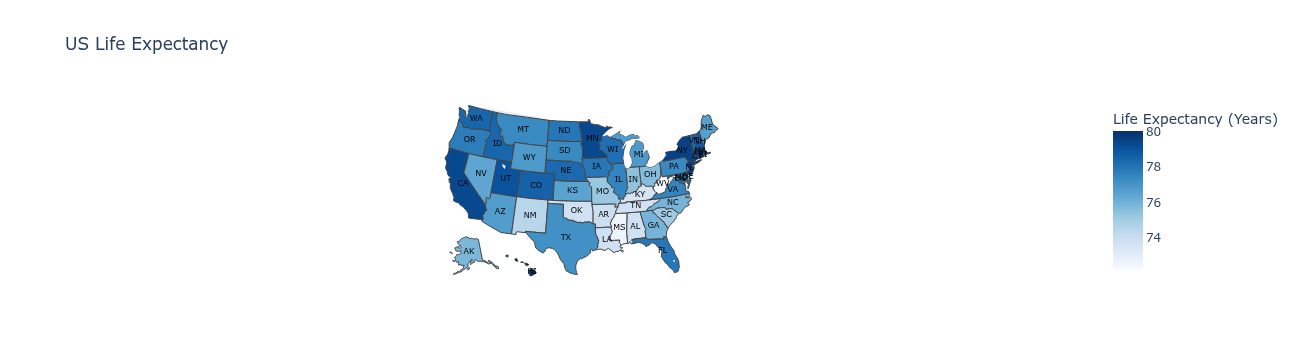

In [274]:
fig = px.choropleth(
    df,
    title="US Life Expectancy",
    locations="State",
    locationmode="USA-states",
    color="Life Expectancy (Years)",
    scope="usa",
    color_continuous_scale="Blues",
    hover_data="Life Expectancy (Years)",
)
fig.add_scattergeo(
    locations=df['State'],
    locationmode='USA-states',
    text=df['Abbreviation'],
    mode='text',
    textfont=dict(size=8, color='black'),
    showlegend=False
)
fig.show()